# Листок № 1. СЛАУ, матрицы, квадратичные формы

## 1.1

Найти общее решение системы линейных уравнений

\[
\begin{cases}
x_1+5x_2-2x_3=-7,\\
-3x_1+x_2+9x_3-5x_4=9,\\
4x_1-8x_2-x_3+7x_4=0.
\end{cases}
\]

**Ответ:**

In [1]:
import sympy as sp

A = sp.Matrix([
    [1, 5, -2, 0],
    [-3, 1, 9, -5],
    [4, -8, -1, 7]
])
b = sp.Matrix([-7, 9, 0])
x1, x2, x3, x4 = sp.symbols('x1 x2 x3 x4')

aug = A.row_join(b)
rref, pivots = aug.rref()
rref, pivots

(Matrix([
 [1, 0, 0,  8/7, -11/7],
 [0, 1, 0, -2/7,  -6/7],
 [0, 0, 1, -1/7,   4/7]]),
 (0, 1, 2))

In [2]:
t = sp.symbols('t')
solution = sp.linsolve((A, b), (x1, x2, x3, x4))
solution

{(-8*x4/7 - 11/7, 2*x4/7 - 6/7, x4/7 + 4/7, x4)}

## 1.2

Найти: а) rref расширенной матрицы и б) общее решение системы

\[
\begin{cases}
5x_1-x_2+5x_3+9x_4-2x_5=-3,\\
3x_1+6x_3+9x_4-x_5=4,\\
2x_1+4x_3+6x_4-x_5=0.
\end{cases}
\]

**Ответ:**

In [3]:
A = sp.Matrix([
    [5, -1, 5, 9, -2],
    [3, 0, 6, 9, -1],
    [2, 0, 4, 6, -1]
])
b = sp.Matrix([-3, 4, 0])
x1, x2, x3, x4, x5 = sp.symbols('x1 x2 x3 x4 x5')

rref, pivots = A.row_join(b).rref()
solution = sp.linsolve((A, b), (x1, x2, x3, x4, x5))
rref, pivots, solution

(Matrix([
 [1, 0, 2, 3, 0, 4],
 [0, 1, 5, 6, 0, 7],
 [0, 0, 0, 0, 1, 8]]),
 (0, 1, 4),
 {(-2*x3 - 3*x4 + 4, -5*x3 - 6*x4 + 7, x3, x4, 8)})

## 1.3

Пусть $(x,y,z,u)$ — решение системы

\[
\begin{cases}
32x+97y+90z+48u=47,\\
35x+84y+91z+54u=40,\\
17x+18y+21z+13u=37.
\end{cases}
\]

Объяснить, почему $y$ можно представить как функцию от $x$ вида $y=a+bx$, и найти $a,b$.

**Ответ:**

In [4]:
A = sp.Matrix([
    [32, 97, 90, 48],
    [35, 84, 91, 54],
    [17, 18, 21, 13]
])
b = sp.Matrix([47, 40, 37])
x, y, z, u = sp.symbols('x y z u')

solution = next(iter(sp.linsolve((A, b), (x, y, z, u))))
y_of_x = sp.simplify(solution[1].subs(u, sp.solve(sp.Eq(x, solution[0]), u)[0]))
a = sp.expand(y_of_x).subs(x, 0)
b_coef = sp.diff(y_of_x, x)
solution, y_of_x, a, b_coef

((36121/10976 - u/10976, 2131*u/5488 + 6325/5488, -10447*u/10976 - 20745/10976, u),
 14027 - 4262*x,
 14027,
 -4262)

## 1.4

Выполнить действия

\[
\begin{pmatrix}
3&0&2\\
0&1&3\\
2&2&0\\
0&1&0
\end{pmatrix}
\begin{pmatrix}
1&2&-1&2\\
-2&-1&1&2\\
2&1&1&2
\end{pmatrix}
+
\begin{pmatrix}
0&-4&6&1\\
2&2&-5&-2\\
2&-2&6&4\\
1&3&0&1
\end{pmatrix}.
\]

**Ответ:**

In [5]:
A = sp.Matrix([
    [3, 0, 2],
    [0, 1, 3],
    [2, 2, 0],
    [0, 1, 0]
])
B = sp.Matrix([
    [1, 2, -1, 2],
    [-2, -1, 1, 2],
    [2, 1, 1, 2]
])
C = sp.Matrix([
    [0, -4, 6, 1],
    [2, 2, -5, -2],
    [2, -2, 6, 4],
    [1, 3, 0, 1]
])
A * B + C

Matrix([
[ 7, 4,  5, 11],
[ 6, 4, -1,  6],
[ 0, 0,  6, 12],
[-1, 2,  1,  3]])

## 1.5

Найти определители порядка $n$, элементы которых заданы условиями:

а) $a_{ij}=\min(i,j)$;

б) $a_{ij}=\max(i,j)$;

в) $a_{ij}=|i-j|$.

**Ответ:**

In [6]:
n = sp.symbols('n', integer=True, positive=True)

def min_matrix(k):
    return sp.Matrix(k, k, lambda i, j: min(i + 1, j + 1))

def max_matrix(k):
    return sp.Matrix(k, k, lambda i, j: max(i + 1, j + 1))

def abs_matrix(k):
    return sp.Matrix(k, k, lambda i, j: abs(i - j))

print([sp.factor(min_matrix(k).det()) for k in range(1, 6)])
print([sp.factor(max_matrix(k).det()) for k in range(1, 7)])
print([sp.factor(abs_matrix(k).det()) for k in range(2, 7)])

print("a) det = 1")
print("b) det = (-1)^(n-1) * n")
print("c) det = (-1)^(n-1) * 2^(n-2) * (n-1), n >= 2")

[1, 1, 1, 1, 1]
[1, -2, 3, -4, 5, -6]
[-1, 4, -12, 32, -80]
a) det = 1
b) det = (-1)^(n-1) * n
c) det = (-1)^(n-1) * 2^(n-2) * (n-1), n >= 2


## 1.6

Найти наибольшее значение определителя шестого порядка, составленного из чисел $-1,0,1$.

**Ответ:**

In [7]:
import itertools
import numpy as np

H = np.array([
    [1, 1, 1, 1, 1, 1],
    [1, 1, -1, -1, 1, -1],
    [1, -1, 1, -1, -1, -1],
    [1, -1, -1, 1, -1, -1],
    [1, 1, -1, -1, -1, 1],
    [1, -1, -1, -1, 1, 1]
])

print(round(abs(np.linalg.det(H))))

160


## 1.7

Матрица $A$ имеет размер $n\times n$, $n=80000$. Диагональные элементы образуют арифметическую прогрессию от $0.99$ до $1.01$. Кроме главной диагонали отличны от нуля только $a_{1,2}=0.57$ и $a_{2,1}=0.03$. Найти определитель $A$ и $\operatorname{tr}(A^{-1})$.

**Ответ:**

In [8]:
import math

n = 80000
d = np.linspace(0.99, 1.01, n)

block_det = d[0] * d[1] - 0.57 * 0.03
log_det = math.log(block_det) + np.sum(np.log(d[2:]))
det_A = math.exp(log_det)

trace_inv = (d[0] + d[1]) / block_det + np.sum(1 / d[2:])

print(det_A)
print(trace_inv)

0.25897911386523903
80002.702766086


## 1.8

Матрица $A$ имеет размер $43000\times43000$. Диагональные элементы образуют геометрическую прогрессию от $1$ до $1.07$. Элементы первой строки образуют арифметическую прогрессию от $1$ до $1.10$. Все остальные внедиагональные элементы равны нулю. Найти наименьший элемент $B=A^{-1}$ и сумму всех элементов $B$.

**Ответ:**

In [9]:
n = 43000

r = math.exp(math.log(1.07) / (n - 1))
d = r ** np.arange(n, dtype=float)
p = 1 + 0.10 * np.arange(n, dtype=float) / (n - 1)

diag_B = 1 / d
offdiag_B = -p[1:] / d[1:]

min_B = min(diag_B.min(), offdiag_B.min())
sum_B = diag_B.sum() + offdiag_B.sum()

print(min_B)
print(sum_B)

-1.0280373831790015
-2054.438267010555


## 1.9

Даны

\[
I=\begin{pmatrix}1&0\\0&1\end{pmatrix},
\qquad
A=\begin{pmatrix}7\gamma&14\gamma\\9\gamma&\gamma\end{pmatrix},
\qquad \gamma=0.057.
\]

\[
S_{m,n}=\sum_{i=m}^{n}A^i,
\qquad
B_m=(I-A)^{-1}A^m.
\]

Найти: 1) наибольший элемент $S_{4,70}$; 2) наибольший элемент $B_4$; 3) наименьшее $k$, такое что при любом $n>k$ наибольший элемент $S_{k,n}$ меньше $0.0002$.

**Ответ:**

In [10]:
gamma = 0.057
I = sp.eye(2)
A = sp.Matrix([
    [7 * gamma, 14 * gamma],
    [9 * gamma, gamma]
])

S = sum((A**i for i in range(4, 71)), sp.zeros(2))
B = (I - A).inv() * A**4

print(float(max(S)))
print(float(max(B)))

for k in range(1, 200):
    limit_matrix = (I - A).inv() * A**k
    if float(max(limit_matrix)) < 0.0002:
        print(k)
        break

3.6096790308034596
3.6111746781096628
89


## 1.10

Дана матрица

\[
M=
\begin{pmatrix}
7&5&5&x\\
2&2&6&9\\
3&x&8&0\\
3&1&1&0
\end{pmatrix}.
\]

Записать определитель в виде многочлена $ax^2+bx+c$ и найти $a,b$.

**Ответ:**

In [11]:
x = sp.symbols('x')
M = sp.Matrix([
    [7, 5, 5, x],
    [2, 2, 6, 9],
    [3, x, 8, 0],
    [3, 1, 1, 0]
])

det_M = sp.expand(M.det())
poly = sp.Poly(det_M, x)

print(det_M)
print("a =", poly.coeff_monomial(x**2))
print("b =", poly.coeff_monomial(x))

16*x**2 - 116*x + 576
a = 16
b = -116


## 1.11

Используя графические возможности, изобразить матрицу размера $100\times100$, каждая строка которой содержит элементы биномиальных коэффициентов по модулю $2$.

**Ответ:**

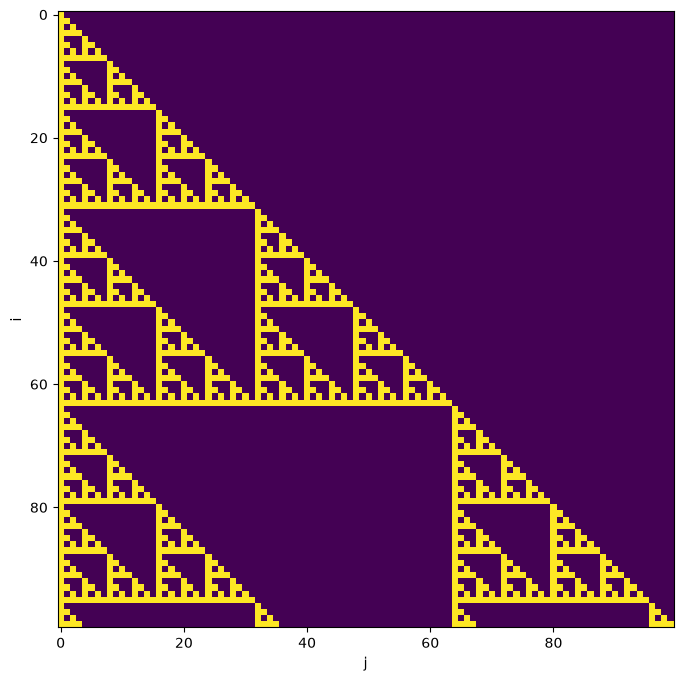

In [12]:
import math
import matplotlib.pyplot as plt

n = 100
C = np.zeros((n, n), dtype=int)

for i in range(n):
    for j in range(i + 1):
        C[i, j] = math.comb(i, j) % 2

plt.figure(figsize=(8, 8))
plt.imshow(C, interpolation="nearest")
plt.xlabel("j")
plt.ylabel("i")
plt.show()

## 1.12

Для матрицы Адамара $H_n$:

а) выписать $H_1,H_2,H_4$;

б) показать $H_4=H_2\otimes H_2$;

в) показать $H_{2^k}=H_2\otimes H_{2^{k-1}}$;

г) изобразить матрицу Адамара для $n=2^6$.

**Ответ:**

In [13]:
H1 = sp.Matrix([[1]])
H2 = sp.Matrix([[1, 1], [1, -1]])
H4 = sp.kronecker_product(H2, H2)
H8 = sp.kronecker_product(H2, H4)
H64 = H2

for _ in range(5):
    H64 = sp.kronecker_product(H2, H64)

print("H1 =")
sp.pprint(H1)
print("H2 =")
sp.pprint(H2)
print("H4 =")
sp.pprint(H4)
print("H4 = H2 ⊗ H2:", H4 == sp.kronecker_product(H2, H2))
print("H8 = H2 ⊗ H4:", H8 == sp.kronecker_product(H2, H4))

H1 =
[1]
H2 =
⎡1  1 ⎤
⎢     ⎥
⎣1  -1⎦
H4 =
⎡1  1   1   1 ⎤
⎢             ⎥
⎢1  -1  1   -1⎥
⎢             ⎥
⎢1  1   -1  -1⎥
⎢             ⎥
⎣1  -1  -1  1 ⎦
H4 = H2 ⊗ H2: True
H8 = H2 ⊗ H4: True


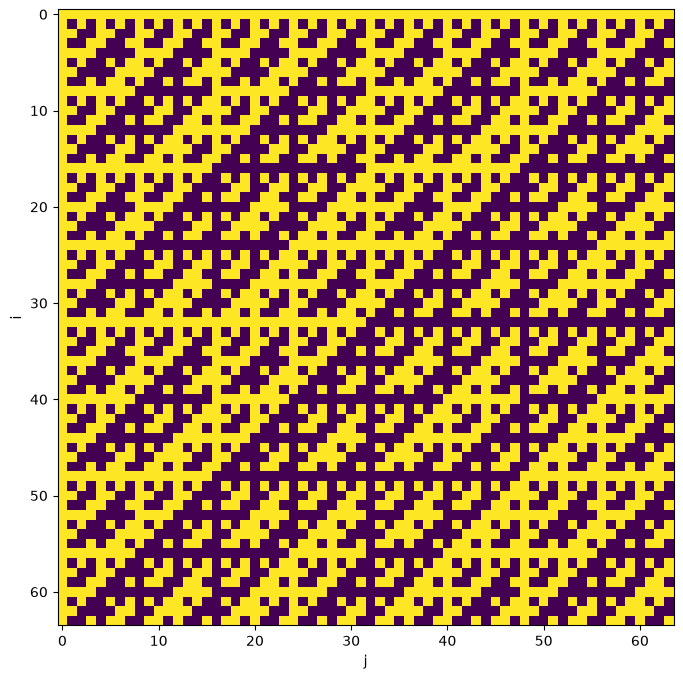

In [14]:
H64_np = np.array(H64.tolist(), dtype=int)

plt.figure(figsize=(8, 8))
plt.imshow(H64_np, interpolation="nearest")
plt.xlabel("j")
plt.ylabel("i")
plt.show()

## 1.13

Дана матрица

\[
A=
\begin{pmatrix}
14&10&21\\
12&15&26\\
18&11&27
\end{pmatrix}.
\]

Пусть $Z$ — собственное значение с наибольшей мнимой частью. Найти $Z$ и соответствующий собственный вектор $X=(1,U,V)$.

**Ответ:**

In [15]:
A = np.array([
    [14, 10, 21],
    [12, 15, 26],
    [18, 11, 27]
], dtype=float)

eigenvalues, eigenvectors = np.linalg.eig(A)
idx = np.argmax(eigenvalues.imag)
Z = eigenvalues[idx]
X = eigenvectors[:, idx] / eigenvectors[0, idx]

print("Z =", Z)
print("X =", X)
print("Im(Z) =", Z.imag)
print("Re(U) =", X[1].real)

Z = (1.9688403308016502+0.3447893484271669j)
X = [ 1.        -0.j          3.74781973+1.33084677j -2.35758843-0.61731802j]
Im(Z) = 0.3447893484271669
Re(U) = 3.747819729394814


## 1.14

Найти минимальный многочлен матрицы

\[
A=
\begin{pmatrix}
-3&7&-6&-1&8&-3&-2\\
1&-5&8&-3&-5&4&-5\\
1&3&-4&6&-2&0&8\\
-1&11&-12&9&3&-3&9\\
-3&11&-12&5&8&-4&6\\
-3&2&1&-4&4&1&-7\\
1&-5&6&-2&-4&3&-2
\end{pmatrix}.
\]

**Ответ:**

In [17]:
A = sp.Matrix([
    [-3, 7, -6, -1, 8, -3, -2],
    [1, -5, 8, -3, -5, 4, -5],
    [1, 3, -4, 6, -2, 0, 8],
    [-1, 11, -12, 9, 3, -3, 9],
    [-3, 11, -12, 5, 8, -4, 6],
    [-3, 2, 1, -4, 4, 1, -7],
    [1, -5, 6, -2, -4, 3, -2]
])

lam = sp.symbols('lam')
charpoly = sp.factor(A.charpoly(lam).as_expr())
print(charpoly)

n = A.shape[0]
m_A = None
for p in range(1, n + 1):
    for q in range(1, n + 1):
        if A**p * (A - sp.eye(n))**q == sp.zeros(n):
            m_A = lam**p * (lam - 1)**q
            break
    if m_A is not None:
        break

print("m_A(lam) =", sp.factor(m_A))

lam**3*(lam - 1)**4
m_A(lam) = lam**3*(lam - 1)**2


## 1.15

Найти собственный ортонормированный базис и матрицу в этом базисе самосопряженного оператора с матрицей

\[
A=
\begin{pmatrix}
17&-8&4\\
-8&17&-4\\
4&-4&11
\end{pmatrix}.
\]

**Ответ:**

In [18]:
A = sp.Matrix([
    [17, -8, 4],
    [-8, 17, -4],
    [4, -4, 11]
])

e1 = sp.Matrix([1, 1, 0]) / sp.sqrt(2)
e2 = sp.Matrix([-1, 1, 4]) / sp.sqrt(18)
e3 = sp.Matrix([2, -2, 1]) / 3

P = sp.Matrix.hstack(e1, e2, e3)
D = sp.simplify(P.T * A * P)

sp.pprint(P)
sp.pprint(D)
print("P.T * P =")
sp.pprint(sp.simplify(P.T * P))

⎡√2  -√2       ⎤
⎢──  ────  2/3 ⎥
⎢2    6        ⎥
⎢              ⎥
⎢√2   √2       ⎥
⎢──   ──   -2/3⎥
⎢2    6        ⎥
⎢              ⎥
⎢    2⋅√2      ⎥
⎢0   ────  1/3 ⎥
⎣     3        ⎦
⎡9  0  0 ⎤
⎢        ⎥
⎢0  9  0 ⎥
⎢        ⎥
⎣0  0  27⎦
P.T * P =
⎡1  0  0⎤
⎢       ⎥
⎢0  1  0⎥
⎢       ⎥
⎣0  0  1⎦


## 1.16

Найти ортогональное преобразование, приводящее к главным осям

\[
f=3x_1^2+8x_1x_2-3x_2^2+4x_3^2-4x_3x_4+x_4^2.
\]

**Ответ:**

In [19]:
A = sp.Matrix([
    [3, 4, 0, 0],
    [4, -3, 0, 0],
    [0, 0, 4, -2],
    [0, 0, -2, 1]
])

P = sp.Matrix([
    [-1/sp.sqrt(5), 2/sp.sqrt(5), 0, 0],
    [2/sp.sqrt(5), 1/sp.sqrt(5), 0, 0],
    [0, 0, 1/sp.sqrt(5), -2/sp.sqrt(5)],
    [0, 0, 2/sp.sqrt(5), 1/sp.sqrt(5)]
])

D = sp.simplify(P.T * A * P)

print("P =")
sp.pprint(P)
print("P.T * P =")
sp.pprint(sp.simplify(P.T * P))
print("P.T * A * P =")
sp.pprint(D)
print("f =", -5*sp.Symbol('y1')**2 + 5*sp.Symbol('y2')**2 + 0*sp.Symbol('y3')**2 + 5*sp.Symbol('y4')**2)

P =
⎡-√5   2⋅√5              ⎤
⎢────  ────   0      0   ⎥
⎢ 5     5                ⎥
⎢                        ⎥
⎢2⋅√5   √5               ⎥
⎢────   ──    0      0   ⎥
⎢ 5     5                ⎥
⎢                        ⎥
⎢             √5   -2⋅√5 ⎥
⎢ 0     0     ──   ──────⎥
⎢             5      5   ⎥
⎢                        ⎥
⎢            2⋅√5    √5  ⎥
⎢ 0     0    ────    ──  ⎥
⎣             5      5   ⎦
P.T * P =
⎡1  0  0  0⎤
⎢          ⎥
⎢0  1  0  0⎥
⎢          ⎥
⎢0  0  1  0⎥
⎢          ⎥
⎣0  0  0  1⎦
P.T * A * P =
⎡-5  0  0  0⎤
⎢           ⎥
⎢0   5  0  0⎥
⎢           ⎥
⎢0   0  0  0⎥
⎢           ⎥
⎣0   0  0  5⎦
f = -5*y1**2 + 5*y2**2 + 5*y4**2


## 1.17

Определить тип кривой второго порядка, каноническое уравнение и каноническую систему координат.

а) $5x^2+4xy+8y^2-32x-56y+80=0$;

б) $5x^2+12xy-22x-12y-19=0$.

**Ответ:**

In [20]:
x, y, u, v = sp.symbols('x y u v')

P_a = sp.Matrix([
    [-2/sp.sqrt(5), 1/sp.sqrt(5)],
    [1/sp.sqrt(5), 2/sp.sqrt(5)]
])
P_b = sp.Matrix([
    [-2/sp.sqrt(13), 3/sp.sqrt(13)],
    [3/sp.sqrt(13), 2/sp.sqrt(13)]
])

print("a)")
print("Тип: эллипс")
print("Центр: (2, 3)")
print("x = 2 - 2*u/sqrt(5) + v/sqrt(5)")
print("y = 3 + u/sqrt(5) + 2*v/sqrt(5)")
print("Каноническое уравнение: u^2/9 + v^2/4 = 1")

print()
print("b)")
print("Тип: гипербола")
print("Центр: (1, 1)")
print("x = 1 - 2*u/sqrt(13) + 3*v/sqrt(13)")
print("y = 1 + 3*u/sqrt(13) + 2*v/sqrt(13)")
print("Каноническое уравнение: v^2/4 - u^2/9 = 1")

a)
Тип: эллипс
Центр: (2, 3)
x = 2 - 2*u/sqrt(5) + v/sqrt(5)
y = 3 + u/sqrt(5) + 2*v/sqrt(5)
Каноническое уравнение: u^2/9 + v^2/4 = 1

b)
Тип: гипербола
Центр: (1, 1)
x = 1 - 2*u/sqrt(13) + 3*v/sqrt(13)
y = 1 + 3*u/sqrt(13) + 2*v/sqrt(13)
Каноническое уравнение: v^2/4 - u^2/9 = 1


## 1.18

При каких значениях параметра $\lambda$ квадратичная форма

\[
Q=x_1^2+4x_2^2+x_3^2+2\lambda x_1x_2+10x_1x_3+6x_2x_3
\]

является положительно определенной?

**Ответ:**

In [21]:
lam = sp.symbols('lam', real=True)

Q = sp.Matrix([
    [1, lam, 5],
    [lam, 4, 3],
    [5, 3, 1]
])

delta1 = Q[:1, :1].det()
delta2 = Q[:2, :2].det()
delta3 = Q.det()

print("Delta1 =", delta1)
print("Delta2 =", sp.factor(delta2))
print("Delta3 =", sp.factor(delta3))
print("Условия: Delta1 > 0, Delta2 > 0, Delta3 > 0")
print("Решение: пустое множество")

Delta1 = 1
Delta2 = -(lam - 2)*(lam + 2)
Delta3 = -lam**2 + 30*lam - 105
Условия: Delta1 > 0, Delta2 > 0, Delta3 > 0
Решение: пустое множество


## 1.19

При каких значениях параметра $\lambda$ квадратичная форма

\[
Q=\lambda x_1^2-2x_2^2-3x_3^2+2x_1x_2-2x_1x_3+2x_2x_3
\]

является отрицательно определенной?

**Ответ:**

In [22]:
lam = sp.symbols('lam', real=True)

Q = sp.Matrix([
    [lam, 1, -1],
    [1, -2, 1],
    [-1, 1, -3]
])

delta1 = Q[:1, :1].det()
delta2 = Q[:2, :2].det()
delta3 = Q.det()

print("Delta1 =", delta1)
print("Delta2 =", delta2)
print("Delta3 =", sp.factor(delta3))
print("Для отрицательной определенности необходимо Delta1 < 0, Delta2 > 0, Delta3 < 0")
print("Delta2 =", delta2, "< 0")
print("Решение: пустое множество")

Delta1 = lam
Delta2 = -2*lam - 1
Delta3 = 5*lam + 3
Для отрицательной определенности необходимо Delta1 < 0, Delta2 > 0, Delta3 < 0
Delta2 = -2*lam - 1 < 0
Решение: пустое множество


## 1.20

Эквивалентны ли над полем вещественных чисел квадратичные формы

\[
Q_1=2x_1^2+9x_2^2+3x_3^2+8x_1x_2-4x_1x_3-10x_2x_3,
\]

\[
Q_2=2x_1^2+3x_2^2+6x_3^2-4x_1x_2-4x_1x_3+8x_2x_3?
\]

**Ответ:**

In [23]:
Q1 = sp.Matrix([
    [2, 4, -2],
    [4, 9, -5],
    [-2, -5, 3]
])

Q2 = sp.Matrix([
    [2, -2, -2],
    [-2, 3, 4],
    [-2, 4, 6]
])

print("Собственные значения Q1:")
sp.pprint(Q1.eigenvals())
print()
print("Собственные значения Q2:")
sp.pprint(Q2.eigenvals())
print()
print("Ранг Q1 =", Q1.rank())
print("Ранг Q2 =", Q2.rank())
print("Инерция Q1: (2, 0, 1)")
print("Инерция Q2: (2, 0, 1)")
print("Формы эквивалентны над R")

Собственные значения Q1:
{0: 1, 7 - √43: 1, √43 + 7: 1}

Собственные значения Q2:
⎧      11   √73     √73   11   ⎫
⎨0: 1, ── - ───: 1, ─── + ──: 1⎬
⎩      2     2       2    2    ⎭

Ранг Q1 = 2
Ранг Q2 = 2
Инерция Q1: (2, 0, 1)
Инерция Q2: (2, 0, 1)
Формы эквивалентны над R
